**Name:** Vikrant Haral     
**Division:** E        
**Batch:** E1              
**Roll No.:** TY-319   
**PRN:** 202401040332

**Assignment 2**


---


**Feature Engineering**

**1. Aim**

To implement feature-engineering techniques on historical road accident data by cleaning raw records, creating informative features, encoding categorical variables and visualizing accident patterns.

**2. Dataset Description**

The supplied train.csv dataset contains 8,210 records and 33 original columns. The columns describe driver characteristics, vehicle details, road conditions, weather, lighting, casualties and accident severity.

The original data was inspected to understand its structure, data types, missing values and class distribution. The dataset source and collection method should be documented using the actual source from which the file was obtained.

**3. STATISTICAL CONCEPTS AND MATHEMATICAL INTUITION**

**3.1 Descriptive Statistics**

Descriptive statistics summarize the main characteristics of a dataset.

**Mean:**

The mean represents the arithmetic average of a numerical variable.
Mean = Sum of all observations / Number of observations
It helps estimate the central value of numerical attributes, such as driver age or vehicle age, when those columns are available and suitable.

**Median:**

The median is the middle value after sorting observations. It is less sensitive to extreme values than the mean.
The median can be useful for imputing missing numerical values when the distribution contains outliers or is skewed.

**Standard Deviation:**

Standard deviation measures the spread of values around the mean.
A low standard deviation indicates that values are relatively close to the mean, while a high standard deviation indicates greater variation.

**Correlation:**

Correlation measures the strength and direction of a linear relationship between two numerical variables.
Pearson's correlation coefficient is calculated as:
r = Cov(X,Y) / (SD(X) × SD(Y))
The coefficient ranges from -1 to +1.
- A value near +1 indicates a strong positive linear relationship.
- A value near -1 indicates a strong negative linear relationship.
- A value near 0 indicates little or no linear relationship.

Correlation does not establish causation. A relationship between two recorded accident attributes does not prove that one causes the other.

**3.2 Mathematical Basis of Feature Engineering**

**Feature 1: Hour of Accident**

If the dataset contains a valid accident time, the hour can be extracted from it.

Hour = Hour component of accident time
This converts a raw time value into a numerical feature that supports comparisons between different hours of the day.

**Feature 2: Weekend Indicator**

Weekend = 1, if the accident date falls on Saturday or Sunday; otherwise 0.
This converts the day of the week into a binary feature for comparing weekday and weekend accident records.

**Feature 3: Night Indicator**

Night = 1, if the recorded accident time falls within the defined nighttime interval; otherwise 0.

The interval must be specified consistently in the implementation. The feature describes the recorded time and does not independently prove that darkness caused an accident.

**Feature 4: Vehicles per Casualty**

Vehicles per Casualty = Number of Vehicles Involved / Number of Casualties
This ratio combines two accident-related numerical attributes into one feature.
If the number of casualties is zero or missing, the ratio is undefined and must be handled explicitly rather than producing an infinite or misleading value.

**Feature 5: Bad Weather Indicator**

Bad Weather = 1, if the recorded weather category belongs to a predefined group of adverse weather conditions; otherwise 0.

The categories included in this group must be selected from the actual values present in the dataset and documented in the notebook.

**Feature 6: Wet Road Indicator**

Wet Road = 1, if the recorded road-surface condition indicates a wet surface; otherwise 0.

The feature must be derived from the actual road-surface categories in the dataset.

**3.3 Interpretation of Statistical Results:**

Statistical analysis helps identify data distributions, unusual values, and relationships between variables. These observations can guide feature selection and further investigation.

The results must be interpreted using the actual computed values and visualizations. No statistical relationship should be claimed unless it is supported by the analysis.


**4. Feature Engineering**

New features were derived from the existing columns to make temporal and environmental patterns easier to analyze. Binary indicators and a numerical vehicle-to-casualty ratio were created, with definitions documented explicitly. The categorical input features were encoded to prepare the data for machine-learning algorithms.

**4.1 Uploading the train.csv file**

In [1]:

from google.colab import files
uploaded = files.upload()

Saving train.csv to train.csv


**4.2 Import the libraries**

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully")


Libraries imported successfully


**4.3 Load and inspect the raw data**

In [3]:

df = pd.read_csv("train.csv")

print("Dataset shape:", df.shape)
print("\nFirst five records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nMissing values per column:")
display(
    df.isna().sum()
      .sort_values(ascending=False)
      .to_frame("Missing_Count")
)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nAccident severity distribution:")
display(df["Accident_severity"].value_counts())


Dataset shape: (8210, 33)

First five records:


,Num,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,Defect_of_vehicle,Area_accident_occured,Lanes_or_Medians,Road_allignment,Types_of_Junction,Road_surface_type,Road_surface_conditions,Light_conditions,Weather_conditions,Type_of_collision,Number_of_vehicles_involved,Number_of_casualties,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,1,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,No defect,Residential areas,NaN,Tangent road with flat terrain,No junction,Asphalt roads,Dry,Daylight,Normal,Collision with roadside-parked vehicles,2,2,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,2,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,No defect,Office areas,Undivided Two way,Tangent road with flat terrain,No junction,Asphalt roads,Dry,Daylight,Normal,Vehicle with vehicle collision,2,2,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,3,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,No defect,Recreational areas,other,NaN,No junction,Asphalt roads,Dry,Daylight,Normal,Collision with roadside objects,2,2,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,No defect,Office areas,other,Tangent road with mild grade and flat terrain,Y Shape,Earth roads,Dry,Darkness - lights lit,Normal,Vehicle with vehicle collision,2,2,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,5,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,No defect,Industrial areas,other,Tangent road with flat terrain,Y Shape,Asphalt roads,Dry,Darkness - lights lit,Normal,Vehicle with vehicle collision,2,2,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury



Column names:
['Num', 'Time', 'Day_of_week', 'Age_band_of_driver', 'Sex_of_driver', 'Educational_level', 'Vehicle_driver_relation', 'Driving_experience', 'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle', 'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians', 'Road_allignment', 'Types_of_Junction', 'Road_surface_type', 'Road_surface_conditions', 'Light_conditions', 'Weather_conditions', 'Type_of_collision', 'Number_of_vehicles_involved', 'Number_of_casualties', 'Vehicle_movement', 'Casualty_class', 'Sex_of_casualty', 'Age_band_of_casualty', 'Casualty_severity', 'Work_of_casuality', 'Fitness_of_casuality', 'Pedestrian_movement', 'Cause_of_accident', 'Accident_severity']

Data types:
Num                             int64
Time                           object
Day_of_week                    object
Age_band_of_driver             object
Sex_of_driver                  object
Educational_level              object
Vehicle_driver_relation        object
Driving_experien

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Num,8210.0,NaN,NaN,NaN,4105.5,2370.167188,1.0,2053.25,4105.5,6157.75,8210.0
Time,8210,1027,18:00:00,76,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Day_of_week,8210,7,Friday,1326,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age_band_of_driver,8210,5,18-30,2728,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex_of_driver,8210,3,Male,7582,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Educational_level,7734,7,Junior high school,5064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vehicle_driver_relation,7870,4,Employee,6373,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Driving_experience,7665,7,5-10yr,2268,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type_of_vehicle,7558,17,Automobile,2130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner_of_vehicle,7889,4,Owner,6972,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values per column:


,Missing_Count
Defect_of_vehicle,2985
Service_year_of_vehicle,2705
Work_of_casuality,2148
Fitness_of_casuality,1770
Type_of_vehicle,652
Driving_experience,545
Educational_level,476
Vehicle_driver_relation,340
Owner_of_vehicle,321
Lanes_or_Medians,267



Duplicate rows: 0

Accident severity distribution:


,count
Accident_severity,
Slight Injury,7082
Serious Injury,1046
Fatal injury,82


**4.4 Clean the data**

In [15]:

df = df.copy()

# Standardize column names
df.columns = df.columns.str.strip()

# Standardize text in categorical columns
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    df[col] = df[col].str.strip()

# Treat blank strings and the literal "nan" as missing.
# Preserve "na" because it can mean not applicable in this dataset.
df = df.replace(r"^\s*$", np.nan, regex=True)
df = df.replace(r"(?i)^nan$", np.nan, regex=True)

# Remove exact duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# Convert accident time to a datetime-like time value
df["Time"] = pd.to_datetime(
    df["Time"], format="%H:%M:%S", errors="coerce"
)

print("Shape after duplicate removal:", df.shape)
print("Missing values after cleaning:")
display(df.isna().sum().sort_values(ascending=False).head(15))


Shape after duplicate removal: (8210, 40)
Missing values after cleaning:


,0
Num,0
Time,0
Day_of_week,0
Age_band_of_driver,0
Sex_of_driver,0
Educational_level,0
Vehicle_driver_relation,0
Driving_experience,0
Type_of_vehicle,0
Owner_of_vehicle,0


**4.5 Handle missing values properly**

In [5]:

# Fill genuine missing categorical values
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    df[col] = df[col].fillna("Unknown")

# Fill missing numeric values using the median
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

print("Remaining missing values:", int(df.isna().sum().sum()))


Remaining missing values: 0


**4.6 Create informative features**

In [6]:

# Extract time-based features
df["Hour"] = df["Time"].dt.hour

df["Time_of_day"] = pd.cut(
    df["Hour"],
    bins=[-1, 5, 11, 16, 20, 23],
    labels=[
        "Late Night",
        "Morning",
        "Afternoon",
        "Evening",
        "Night"
    ]
).astype("object")

# Day-of-week feature
weekend_days = ["Saturday", "Sunday"]

df["Is_weekend"] = (
    df["Day_of_week"].isin(weekend_days).astype(int)
)

# Environmental indicators
light = df["Light_conditions"].astype(str).str.lower()
weather = df["Weather_conditions"].astype(str).str.lower()
surface = df["Road_surface_conditions"].astype(str).str.lower()

df["Is_night"] = light.str.contains(
    "darkness", na=False
).astype(int)

df["Is_bad_weather"] = weather.str.contains(
    r"rain|storm|fog|snow", regex=True, na=False
).astype(int)

df["Is_wet_road"] = surface.str.contains(
    r"wet|mud|snow|flood", regex=True, na=False
).astype(int)

# Numerical derived feature
df["Vehicles_per_casualty"] = (
    df["Number_of_vehicles_involved"]
    / df["Number_of_casualties"].replace(0, np.nan)
)

print("New engineered features:")
display(df[[
    "Hour", "Time_of_day", "Is_weekend", "Is_night",
    "Is_bad_weather", "Is_wet_road", "Vehicles_per_casualty"
]].head())


New engineered features:


,Hour,Time_of_day,Is_weekend,Is_night,Is_bad_weather,Is_wet_road,Vehicles_per_casualty
0,17,Evening,0,0,0,0,1.0
1,17,Evening,0,0,0,0,1.0
2,17,Evening,0,0,0,0,1.0
3,1,Late Night,1,1,0,0,1.0
4,1,Late Night,1,1,0,0,1.0


**4.7 Handling Missing Values in Vehicles per Casualty Ratio**

In [22]:

df["Vehicles_per_casualty"] = df[
    "Vehicles_per_casualty"
].replace([np.inf, -np.inf], np.nan)

df["Vehicles_per_casualty"] = df[
    "Vehicles_per_casualty"
].fillna(
    df["Vehicles_per_casualty"].median()
)

print(
    "Missing values in Vehicles_per_casualty:",
    df["Vehicles_per_casualty"].isna().sum()
)


Missing values in Vehicles_per_casualty: 0


**4.8. Apply feature encoding**

In [16]:

# Remove the raw identifier and raw time from model inputs.
# Keep the engineered Hour and Time_of_day features.
model_df = df.drop(
    columns=["Num", "Time"],
    errors="ignore"
).copy()

# Target: the outcome we want to study
target = "Accident_severity"

# Do not encode the target as an ordinary input feature.
X = model_df.drop(columns=[target])
y = model_df[target]

# One-hot encode categorical input variables.
X_encoded = pd.get_dummies(
    X,
    columns=X.select_dtypes(
        include=["object", "category"]
    ).columns.tolist(),
    dtype=int
)

print("Original input features:", X.shape[1])
print("Encoded input features:", X_encoded.shape[1])

display(X_encoded.head())

# Save feature matrix and target separately
X_encoded.to_csv("roadguard_encoded_features.csv", index=False)
y.to_csv("roadguard_target.csv", index=False)

print("Encoded features and target saved.")


Original input features: 37
Encoded input features: 223


,Number_of_vehicles_involved,Number_of_casualties,Hour,Is_weekend,Is_night,Is_bad_weather,Is_wet_road,Vehicles_per_casualty,Day_of_week_Friday,Day_of_week_Monday,Day_of_week_Saturday,Day_of_week_Sunday,Day_of_week_Thursday,Day_of_week_Tuesday,Day_of_week_Wednesday,Age_band_of_driver_18-30,Age_band_of_driver_31-50,Age_band_of_driver_Over 51,Age_band_of_driver_Under 18,Age_band_of_driver_Unknown,Sex_of_driver_Female,Sex_of_driver_Male,Sex_of_driver_Unknown,Educational_level_Above high school,Educational_level_Elementary school,Educational_level_High school,Educational_level_Illiterate,Educational_level_Junior high school,Educational_level_Unknown,Educational_level_Writing & reading,Vehicle_driver_relation_Employee,Vehicle_driver_relation_Other,Vehicle_driver_relation_Owner,Vehicle_driver_relation_Unknown,Driving_experience_1-2yr,Driving_experience_2-5yr,Driving_experience_5-10yr,Driving_experience_Above 10yr,Driving_experience_Below 1yr,Driving_experience_No Licence,Driving_experience_Unknown,Driving_experience_unknown,Type_of_vehicle_Automobile,Type_of_vehicle_Bajaj,Type_of_vehicle_Bicycle,Type_of_vehicle_Long lorry,Type_of_vehicle_Lorry (11?40Q),Type_of_vehicle_Lorry (41?100Q),Type_of_vehicle_Motorcycle,Type_of_vehicle_Other,Type_of_vehicle_Pick up upto 10Q,Type_of_vehicle_Public (12 seats),Type_of_vehicle_Public (13?45 seats),Type_of_vehicle_Public (> 45 seats),Type_of_vehicle_Ridden horse,Type_of_vehicle_Special vehicle,Type_of_vehicle_Stationwagen,Type_of_vehicle_Taxi,Type_of_vehicle_Turbo,Type_of_vehicle_Unknown,Owner_of_vehicle_Governmental,Owner_of_vehicle_Organization,Owner_of_vehicle_Other,Owner_of_vehicle_Owner,Owner_of_vehicle_Unknown,Service_year_of_vehicle_1-2yr,Service_year_of_vehicle_2-5yrs,Service_year_of_vehicle_5-10yrs,Service_year_of_vehicle_Above 10yr,Service_year_of_vehicle_Below 1yr,Service_year_of_vehicle_Unknown,Defect_of_vehicle_5,Defect_of_vehicle_7,Defect_of_vehicle_No defect,Defect_of_vehicle_Unknown,Area_accident_occured_Church areas,Area_accident_occured_Hospital areas,Area_accident_occured_Industrial areas,Area_accident_occured_Market areas,Area_accident_occured_Office areas,Area_accident_occured_Other,Area_accident_occured_Outside rural areas,Area_accident_occured_Recreational areas,Area_accident_occured_Residential areas,Area_accident_occured_Rural village areas,Area_accident_occured_Rural village areasOffice areas,Area_accident_occured_School areas,Area_accident_occured_Unknown,Lanes_or_Medians_Double carriageway (median),Lanes_or_Medians_One way,Lanes_or_Medians_Two-way (divided with broken lines road marking),Lanes_or_Medians_Two-way (divided with solid lines road marking),Lanes_or_Medians_Undivided Two way,Lanes_or_Medians_Unknown,Lanes_or_Medians_other,Road_allignment_Escarpments,Road_allignment_Gentle horizontal curve,Road_allignment_Sharp reverse curve,Road_allignment_Steep grade downward with mountainous terrain,Road_allignment_Steep grade upward with mountainous terrain,Road_allignment_Tangent road with flat terrain,Road_allignment_Tangent road with mild grade and flat terrain,Road_allignment_Tangent road with mountainous terrain and,Road_allignment_Tangent road with rolling terrain,Road_allignment_Unknown,Types_of_Junction_Crossing,Types_of_Junction_No junction,Types_of_Junction_O Shape,Types_of_Junction_Other,Types_of_Junction_T Shape,Types_of_Junction_Unknown,Types_of_Junction_X Shape,Types_of_Junction_Y Shape,Road_surface_type_Asphalt roads,Road_surface_type_Asphalt roads with some distress,Road_surface_type_Earth roads,Road_surface_type_Gravel roads,Road_surface_type_Other,Road_surface_type_Unknown,Road_surface_conditions_Dry,Road_surface_conditions_Flood over 3cm. deep,Road_surface_conditions_Snow,Road_surface_conditions_Wet or damp,Light_conditions_Darkness - lights lit,Light_conditions_Darkness - lights unlit,Light_conditions_Darkness - no lighting,Light_conditions_Daylight,Weather_conditions_Cloudy,Weather_conditions_Fog or mist,Weather_conditions_Normal,Weather_conditions_Othe

Encoded features and target saved.


**4.9 Checking Missing and Infinite Values in Encoded Features**

In [23]:

print("Missing values in encoded features:",
      int(X_encoded.isna().sum().sum()))

print("Infinite values in encoded features:",
      int(np.isinf(X_encoded.select_dtypes(
          include=np.number
      )).sum().sum()))


Missing values in encoded features: 0
Infinite values in encoded features: 0


**4.10 Create the visualizations**

**4.10.1 Chart 1: Accident severity**

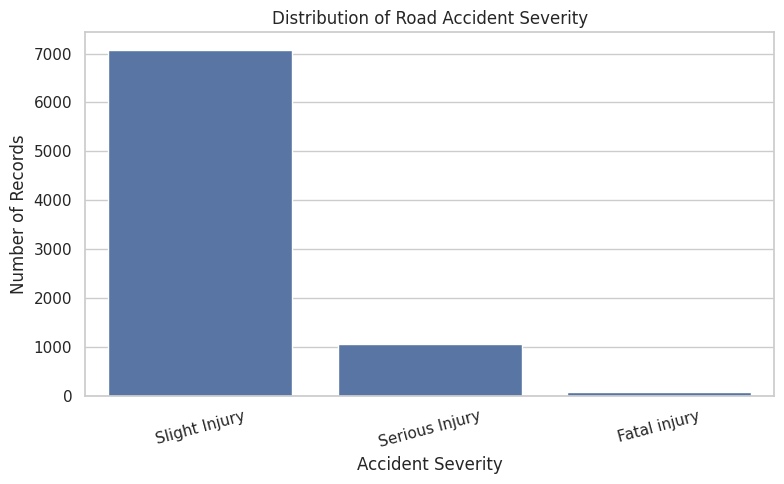

In [8]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Accident_severity",
    order=df["Accident_severity"].value_counts().index
)

plt.title("Distribution of Road Accident Severity")
plt.xlabel("Accident Severity")
plt.ylabel("Number of Records")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


**4.10.2 Chart 2: Accidents by hour**

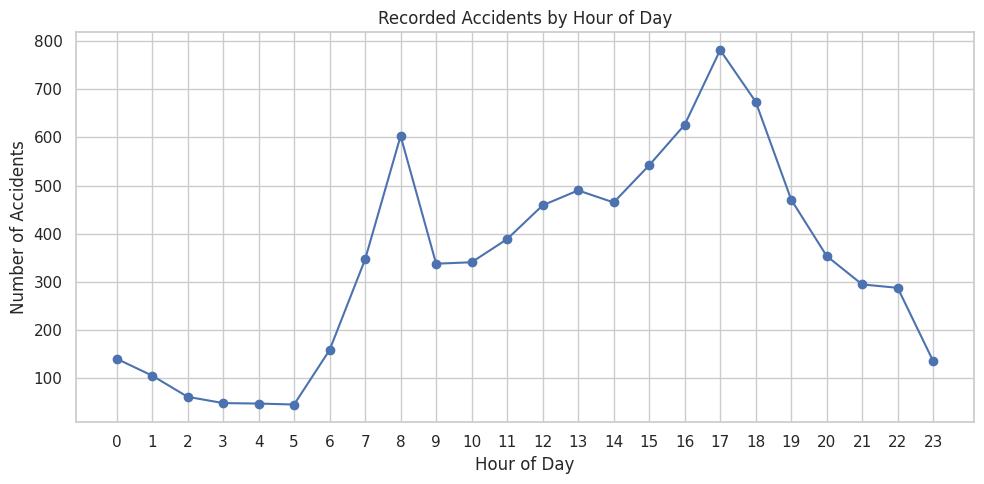

In [9]:

hour_counts = df["Hour"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(hour_counts.index, hour_counts.values, marker="o")

plt.title("Recorded Accidents by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Accidents")
plt.xticks(range(24))
plt.tight_layout()
plt.show()


**4.10.3 Chart 3: Day and hour heatmap**

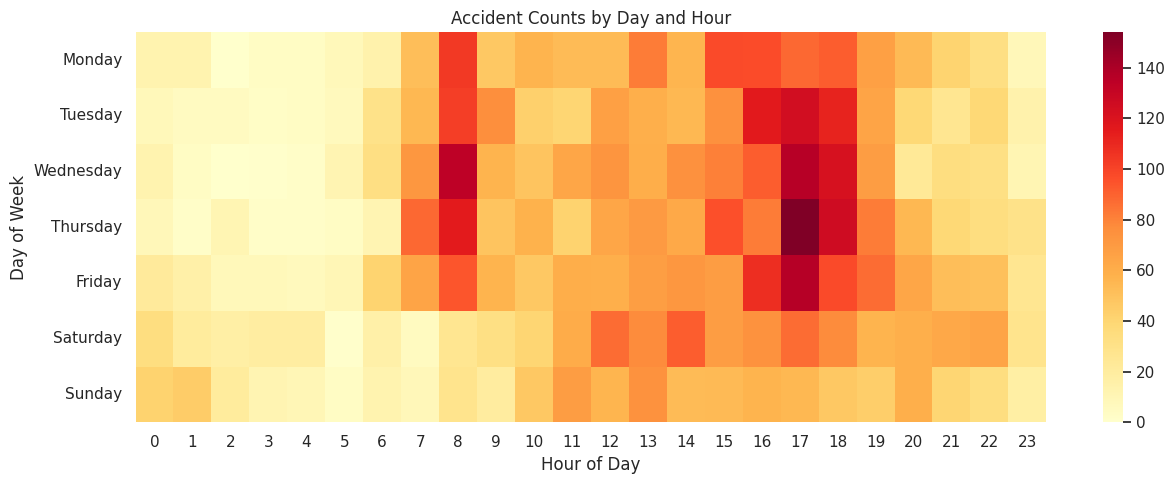

In [10]:

heatmap_data = pd.crosstab(
    df["Day_of_week"],
    df["Hour"]
)

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

heatmap_data = heatmap_data.reindex(day_order)

plt.figure(figsize=(13, 5))
sns.heatmap(heatmap_data, cmap="YlOrRd")

plt.title("Accident Counts by Day and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.tight_layout()
plt.show()


**4.10.4 Chart 4: Severity and weather**

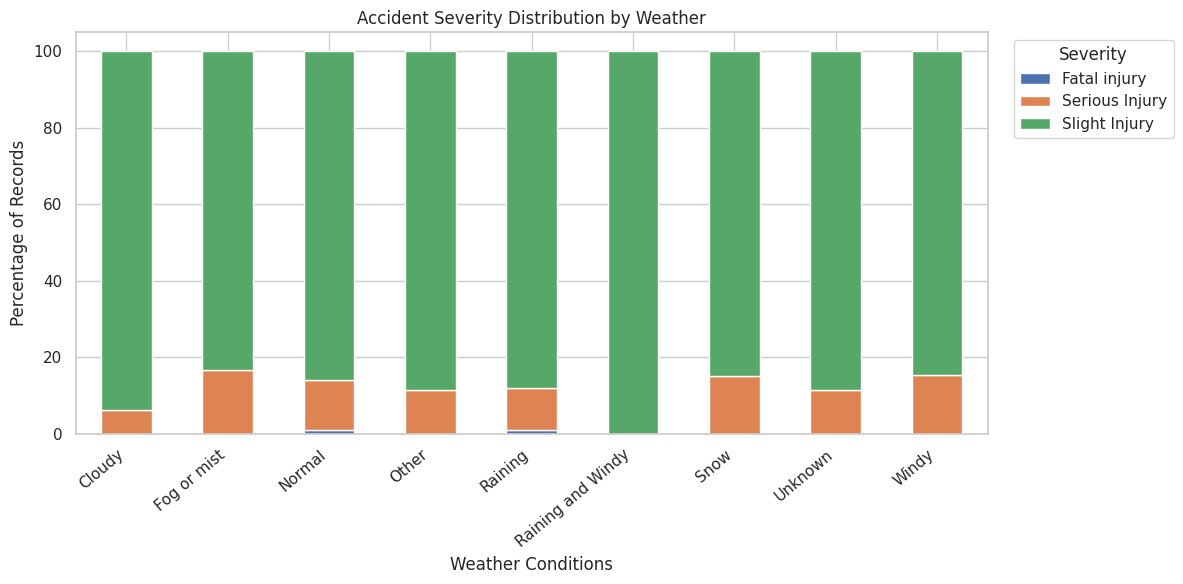

In [17]:

weather_severity = pd.crosstab(
    df["Weather_conditions"],
    df["Accident_severity"],
    normalize="index"
) * 100

weather_severity.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Accident Severity Distribution by Weather")
plt.xlabel("Weather Conditions")
plt.ylabel("Percentage of Records")
plt.legend(title="Severity", bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()


**4.10.5 Chart 5: Numerical correlation heatmap**

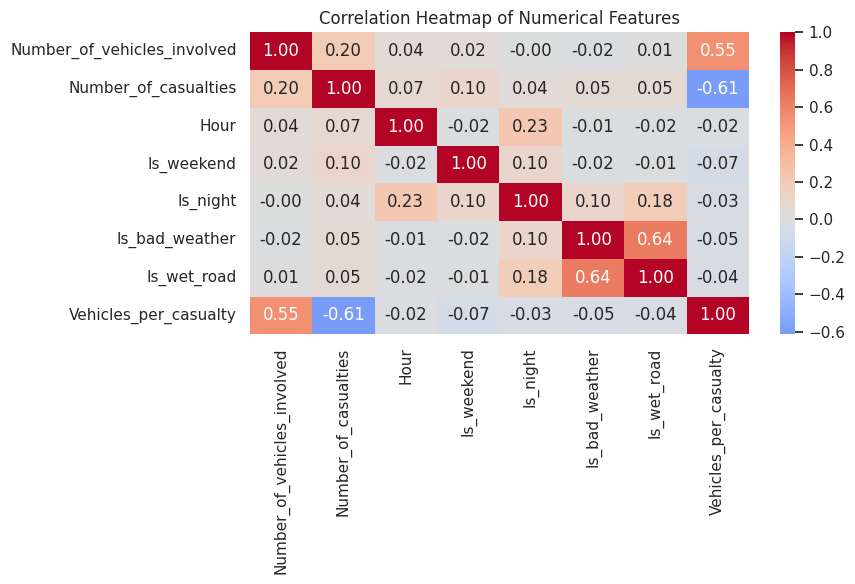

In [12]:

numeric_for_corr = df.select_dtypes(include=np.number).drop(
    columns=["Num"], errors="ignore"
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    numeric_for_corr.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()



**4.10.6 Chart 6: Engineered features and accident severity**


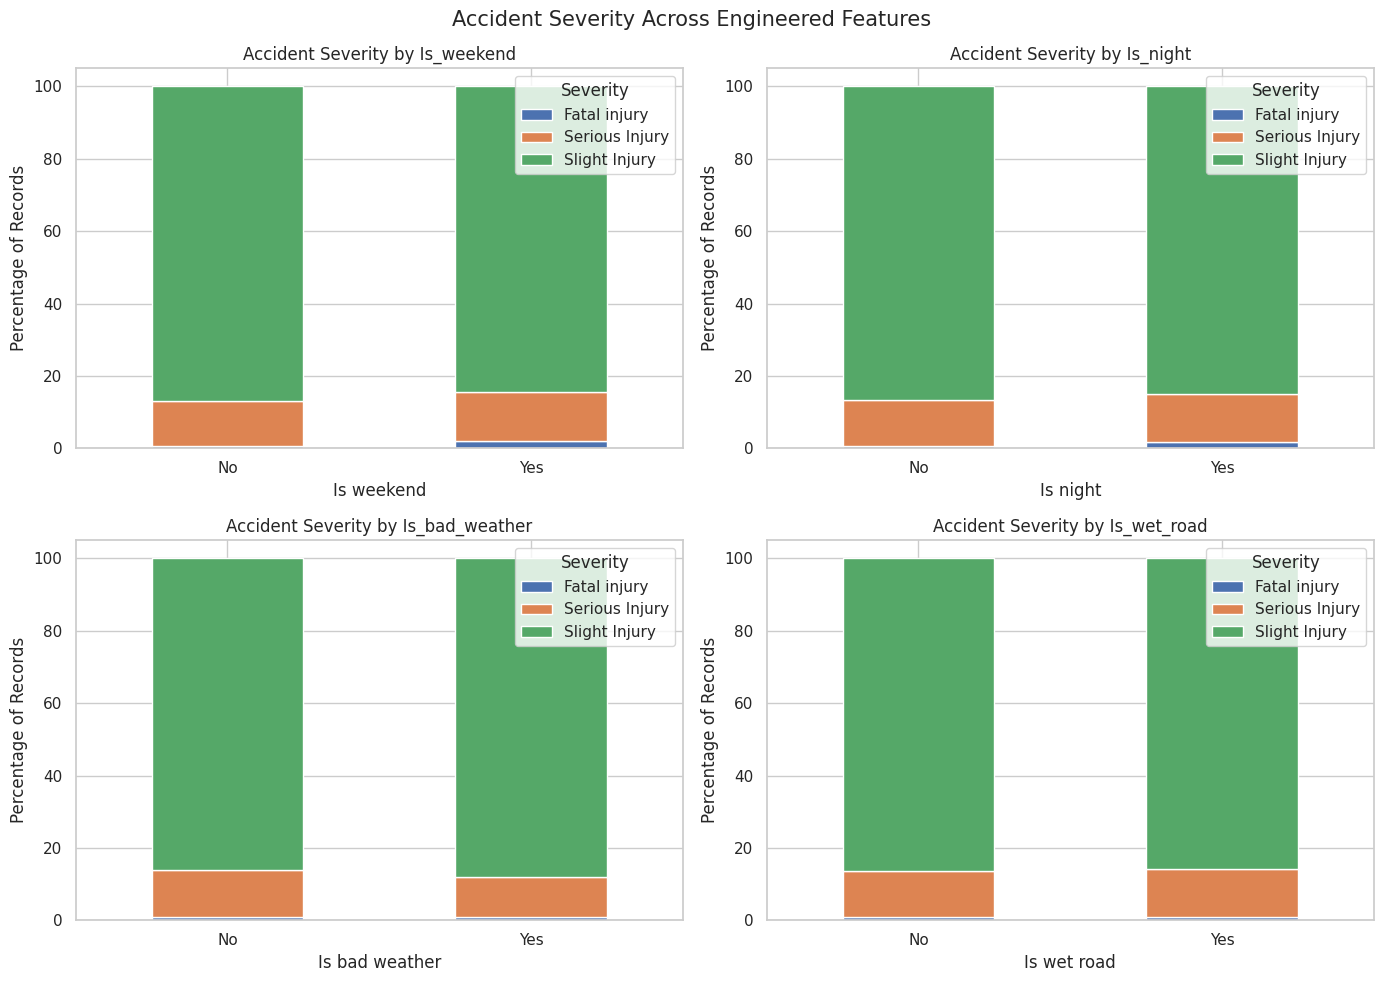

In [21]:

engineered_features = [
    "Is_weekend",
    "Is_night",
    "Is_bad_weather",
    "Is_wet_road"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for feature, ax in zip(engineered_features, axes.flatten()):
    plot_data = df.copy()
    plot_data[feature] = plot_data[feature].map({
        0: "No",
        1: "Yes"
    })

    severity_pct = pd.crosstab(
        plot_data[feature],
        plot_data["Accident_severity"],
        normalize="index"
    ) * 100

    severity_pct.plot(
        kind="bar",
        stacked=True,
        ax=ax
    )

    ax.set_title(f"Accident Severity by {feature}")
    ax.set_xlabel(feature.replace("_", " "))
    ax.set_ylabel("Percentage of Records")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Severity")

plt.suptitle(
    "Accident Severity Across Engineered Features",
    fontsize=15
)
plt.tight_layout()
plt.show()


**4.11 Export the cleaned and engineered dataset**

In [18]:

df.to_csv("roadguard_cleaned_engineered.csv", index=False)

print("Final dataset shape:", df.shape)
print("Encoded feature matrix shape:", X_encoded.shape)
print("Target distribution:")
display(y.value_counts())

print("\nFiles ready for submission:")
print("1. roadguard_cleaned_engineered.csv")
print("2. roadguard_encoded_features.csv")
print("3. roadguard_target.csv")


Final dataset shape: (8210, 40)
Encoded feature matrix shape: (8210, 223)
Target distribution:


,count
Accident_severity,
Slight Injury,7082
Serious Injury,1046
Fatal injury,82



Files ready for submission:
1. roadguard_cleaned_engineered.csv
2. roadguard_encoded_features.csv
3. roadguard_target.csv


**4.12 Downloading the files**

In [19]:

from google.colab import files

files.download("roadguard_cleaned_engineered.csv")
files.download("roadguard_encoded_features.csv")
files.download("roadguard_target.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**5. Conclusion**

The feature-engineering pipeline transforms the original accident records into a cleaner and more informative representation. The resulting dataset provides a foundation for further severity classification, temporal analysis and subsequent geographic hotspot analysis when suitable location data is available.